# Clustering

## Imports, choix d'une décennie et chargement des fichiers

In [26]:
import collections
import os
import string
import sys
import yake
import pandas as pd
from nltk import word_tokenize
from nltk.corpus import stopwords
from pprint import pprint
from sklearn.cluster import KMeans
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import PCA
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.distance import cosine

In [2]:
import nltk

nltk.download('punkt')
nltk.download("punkt_tab")

[nltk_data] Downloading package punkt to
[nltk_data]     /Users/alexiawaucquez/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     /Users/alexiawaucquez/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [9]:
data_path = "../txt/"

In [10]:
DECADE = '1910'

In [11]:
files = [f for f in sorted(os.listdir(data_path)) if f"_{DECADE[:-1]}" in f]

In [12]:
texts = [open(data_path + f, "r", encoding="utf-8").read() for f in files]

## Vectorisation

In [13]:
# Création d'une fonction de pré-traitement
def preprocessing(text, stem=True):
    """ Tokenize text and remove punctuation """
    text = text.translate(string.punctuation)
    tokens = word_tokenize(text)
    return tokens

In [14]:
vectorizer = TfidfVectorizer(
    tokenizer=preprocessing,
    stop_words=stopwords.words('french'),
    max_df=0.5,
    min_df=0.1,
    lowercase=True)

In [15]:
tfidf_vectors = vectorizer.fit_transform(texts)

/Users/alexiawaucquez/tac/.venv/lib/python3.11/site-packages/sklearn/feature_extraction/text.py:527: UserWarning: The parameter 'token_pattern' will not be used since 'tokenizer' is not None'
  warnings.warn(


## Clustering

In [55]:
N_CLUSTERS = 3

In [56]:
km_model = KMeans(n_clusters=N_CLUSTERS)

In [57]:
clusters = km_model.fit_predict(tfidf_vectors)

In [58]:
clustering = collections.defaultdict(list)

for idx, label in enumerate(clusters):
    clustering[label].append(files[idx])

In [59]:
pprint(dict(clustering))

{np.int32(0): ['KB_JB838_1910-01-07_01-00003.txt',
               'KB_JB838_1910-01-17_01-00002.txt',
               'KB_JB838_1910-01-22_01-00003.txt',
               'KB_JB838_1910-01-22_01-00004.txt',
               'KB_JB838_1910-01-29_01-00003.txt',
               'KB_JB838_1910-01-30_01-00003.txt',
               'KB_JB838_1910-02-07_01-00002.txt',
               'KB_JB838_1910-02-09_01-00002.txt',
               'KB_JB838_1910-02-09_01-00004.txt',
               'KB_JB838_1910-02-18_01-00001.txt',
               'KB_JB838_1910-02-24_01-00003.txt',
               'KB_JB838_1910-02-25_01-00002.txt',
               'KB_JB838_1910-03-05_01-00008.txt',
               'KB_JB838_1910-03-06_01-00005.txt',
               'KB_JB838_1910-03-16_02-00001.txt',
               'KB_JB838_1910-03-19_01-00003.txt',
               'KB_JB838_1910-03-28_01-00004.txt',
               'KB_JB838_1910-04-02_01-00004.txt',
               'KB_JB838_1910-04-10_01-00001.txt',
               'KB_JB838_1910-0

In [60]:
pca = PCA(n_components=2)
reduced_vectors = pca.fit_transform(tfidf_vectors.toarray())

In [61]:
reduced_vectors[:10]

array([[ 0.10682943, -0.53231762],
       [-0.33401337,  0.12721165],
       [ 0.2234679 , -0.33813833],
       [ 0.6005316 ,  0.30108021],
       [ 0.41518416, -0.00272616],
       [-0.29112631,  0.10829669],
       [-0.25028559,  0.03569582],
       [-0.12982622, -0.14191044],
       [-0.28893612,  0.07482188],
       [-0.26858278,  0.05405482]])

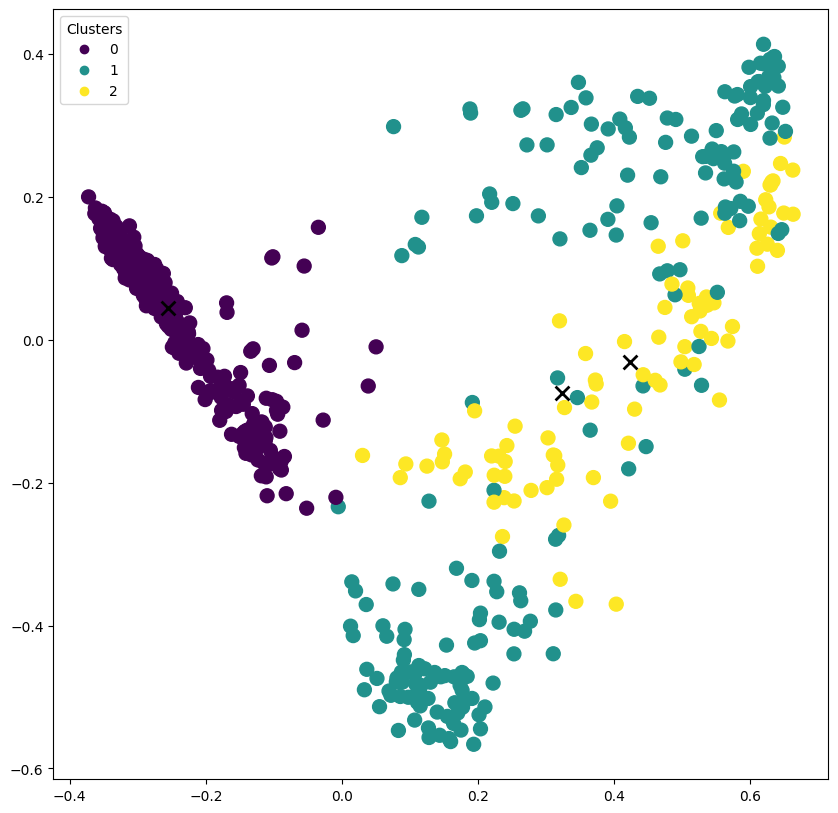

In [62]:
x_axis = reduced_vectors[:, 0]
y_axis = reduced_vectors[:, 1]

plt.figure(figsize=(10,10))
scatter = plt.scatter(x_axis, y_axis, s=100, c=clusters)

# Ajouter les centroïdes
centroids = pca.transform(km_model.cluster_centers_)
plt.scatter(centroids[:, 0], centroids[:, 1],  marker = "x", s=100, linewidths = 2, color='black')

# Ajouter la légende
plt.legend(handles=scatter.legend_elements()[0], labels=set(clusters), title="Clusters")

## Extraction de mots clefs

In [ ]:
# Instancier l'extracteur de mots clés
kw_extractor = yake.KeywordExtractor(lan="fr", top=50)
kw_extractor

In [28]:
#extraction de bigrammes
for f in sorted(files):
    text = open(os.path.join(data_path, f), 'r', encoding="utf-8").read()
    keywords = kw_extractor.extract_keywords(text)
    kept = []
    for kw, score in keywords:
        words = kw.split()
        if len(words) == 2:
            kept.append(kw)
    print(f"{f} mentions these keywords: {', '.join(kept)}...")

KB_JB838_1910-01-06_01-00008.txt mentions these keywords: EXTRACTION COMPLETEMENT, fie Utft, Agence Rossel, RUE ROYALE, irirm mriToi, piano noir, bas prix...
KB_JB838_1910-01-07_01-00003.txt mentions these keywords: Hakluyt Sdcfety, Blousa Hakluyt, collection mie, Philippe Demoulin, précisément ttanmialent, dit qu’il, pêche belge, roi Albert, qu’il serait, décembre dernier, eaux belges...
KB_JB838_1910-01-09_01-00010.txt mentions these keywords: Agence Rossel, Bon prix, RUE NEUVE, vendre Rue, ÉPOQUES rue...
KB_JB838_1910-01-13_01-00007.txt mentions these keywords: Agence Rossel, Tne fille, gros dem, demande servante, Jne fille, dem. serv., Tno fille, fem. dem...
KB_JB838_1910-01-16_01-00009.txt mentions these keywords: Agence Rossel, louer maison, RIDEAUX guipure, GRANDS RIDEAUX, TABLE blancs, BELLE MAISON, louer belle, l’Agence Rossel, guipure blanc, RIDEAUX crème...
KB_JB838_1910-01-17_01-00002.txt mentions these keywords: princesse Louise, prince Philippe, roi Léopold, Dieu qu’il, a

In [29]:
#extraction de trigrammes
for f in sorted(files):
    text = open(os.path.join(data_path, f), 'r', encoding="utf-8").read()
    keywords = kw_extractor.extract_keywords(text)
    kept = []
    for kw, score in keywords:
        words = kw.split()
        if len(words) == 3:
            kept.append(kw)
    print(f"{f} mentions these keywords: {', '.join(kept)}...")

KB_JB838_1910-01-06_01-00008.txt mentions these keywords: miriiirianiiiinnnw n irirm, COMPLETEMENT SANS DOULEUR, OCCASIONS GARANTIS PIANOS...
KB_JB838_1910-01-07_01-00003.txt mentions these keywords: Blousa Hakluyt Sdcfety, barques à voiles, collection mie possédait, pêche belge L’administration, conseil dit qu’il, collection d’ouvrages précieux, uno collection d’ouvrages, rassembler uno collection...
KB_JB838_1910-01-09_01-00010.txt mentions these keywords: Adresse Agence Rossel, vendre Rue Wa-uiwecmans...
KB_JB838_1910-01-13_01-00007.txt mentions these keywords: fille demande place, Tne fille dés., Tno fille dem., Jne fille dem....
KB_JB838_1910-01-16_01-00009.txt mentions these keywords: RIDEAUX guipure blanc, GRANDS RIDEAUX crème, louer belle maison, S’adir Agence Rossel, louer maison moderne...
KB_JB838_1910-01-17_01-00002.txt mentions these keywords: Philippe de Cobourg, Réponse du Roi, diu roi Léopold...
KB_JB838_1910-01-22_01-00003.txt mentions these keywords: d’un jeune homme.

## Nuage de mots

In [30]:
from collections import Counter
from wordcloud import WordCloud
import os
import nltk
nltk.download('stopwords')
from nltk.corpus import stopwords
from IPython.display import Image

[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/alexiawaucquez/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [31]:
# Stopwords (Idem que dans s1)
sw = stopwords.words("french")
sw += ["les", "plus", "cette", "fait", "faire", "être", "deux", "comme", "dont", "tout",
       "ils", "bien", "sans", "peut", "tous", "après", "ainsi", "donc", "cet", "sous",
       "celle", "entre", "encore", "toutes", "pendant", "moins", "dire", "cela", "non",
       "faut", "trois", "aussi", "dit", "avoir", "doit", "contre", "depuis", "autres",
       "van", "het", "autre", "jusqu", "ville", "rossel", "dem"]
sw = set(sw)


In [39]:
# Ecrire tout le contenu dans un fichier temporaire
temp_path = '../tmp'
if not os.path.exists(temp_path):
    os.mkdir(temp_path)
with open(os.path.join(temp_path, f'{DECADE}.txt'), 'w', encoding='utf-8') as f:
    f.write(' '.join(texts))

In [45]:
def clean_text(DECADE, folder=None):
    if folder is None:
        input_path = f"{DECADE}.txt"
        output_path = f"{DECADE}_clean.txt"
    else:
        input_path = f"{folder}/{DECADE}.txt"
        output_path = f"{folder}/{DECADE}_clean.txt"
    output = open(output_path, "w", encoding='utf-8')
    with open(input_path, 'r', encoding='utf-8') as f:
        text = f.read()
        words = nltk.wordpunct_tokenize(text)
        kept = [w.upper() for w in words if len(w) > 2 and w.isalpha() and w.lower() not in sw]
        kept_string = " ".join(kept)
        output.write(kept_string)
    return f'Output has been written in {output_path}!'

In [46]:
clean_text(DECADE, folder=temp_path)

TimeoutError: regular-expression match exceeded its 5.0s time limit; the pattern '\\w+|[^\\w\\s]+' may be pathological for this input (catastrophic backtracking / ReDoS). Pass timeout=None to disable the limit for a trusted pattern.

In [38]:
# Vérifier le résultat
with open(os.path.join(temp_path, f'{DECADE}_clean.txt'), 'r', encoding='utf-8') as f:
    after = f.read()

after[:500]

'TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT TXT '